In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("../data/Student_Performance.csv")

In [8]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [9]:
df.shape

(10000, 6)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [11]:
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [13]:
print(df.duplicated().sum())

127


In [14]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


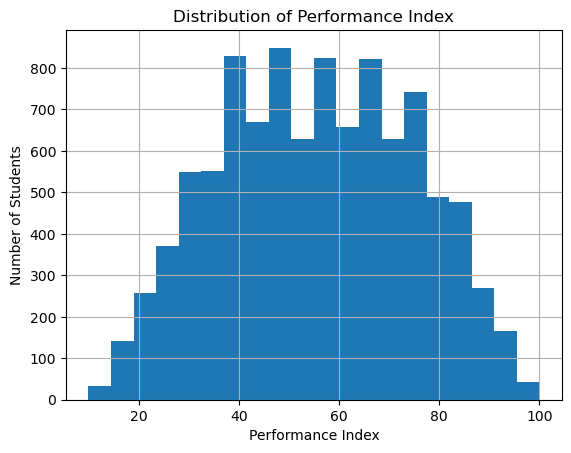

In [15]:
df["Performance Index"].hist(bins=20)

plt.xlabel("Performance Index")
plt.ylabel("Number of Students")
plt.title("Distribution of Performance Index")
plt.show()

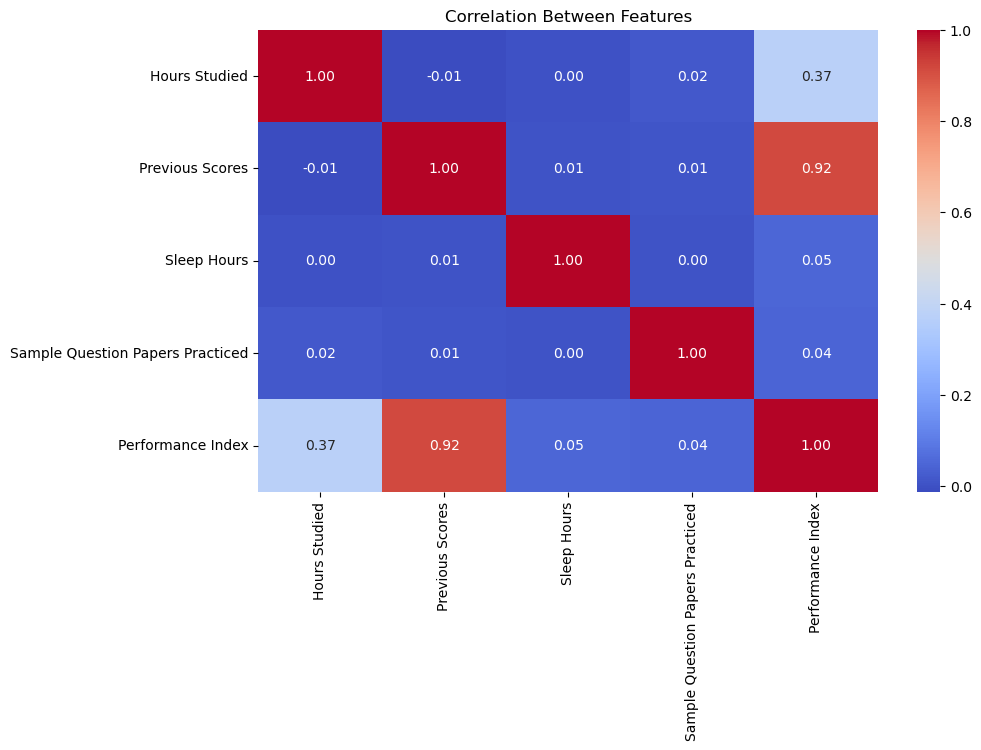

In [16]:
plt.figure(figsize=(10, 6))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Features")
plt.show()

In [17]:
df["Extracurricular Activities"].value_counts()

Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64

In [18]:
df[df.duplicated()].head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
915,9,52,No,5,9,48.0
1477,7,61,Yes,6,8,54.0
1601,5,99,No,7,5,89.0
1786,2,62,Yes,9,4,40.0
2026,5,87,Yes,6,7,74.0


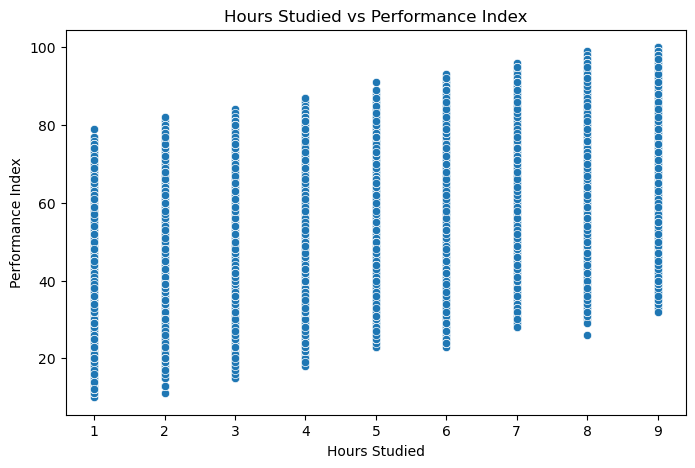

In [19]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Hours Studied", y="Performance Index")
plt.title("Hours Studied vs Performance Index")
plt.show()

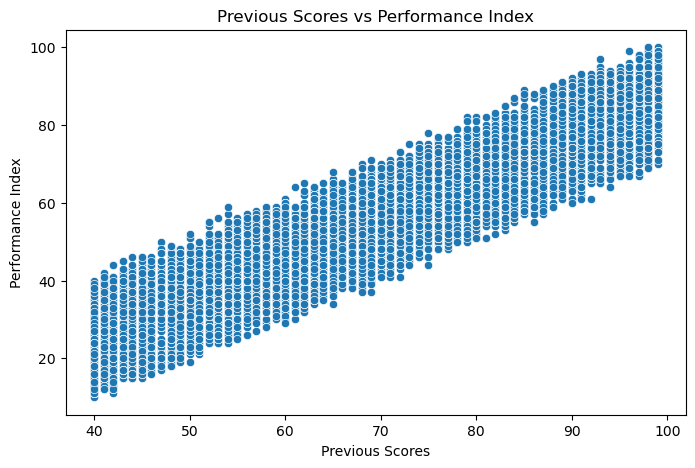

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Previous Scores", y="Performance Index")

plt.title("Previous Scores vs Performance Index")
plt.show()

In [21]:
# check categorical values
print(df["Extracurricular Activities"].value_counts())
# check data types
print(df.dtypes)
# check duplicate rows
print("Duplicate rows:", df.duplicated().sum())
# check unique values in each column
for col in df.columns:
    print(col, ":", df[col].nunique())

Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64
Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities           object
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object
Duplicate rows: 127
Hours Studied : 9
Previous Scores : 60
Extracurricular Activities : 2
Sleep Hours : 6
Sample Question Papers Practiced : 10
Performance Index : 91


In [22]:
df_encoded = df.copy()

df_encoded["Extracurricular Activities"] = (
    df_encoded["Extracurricular Activities"].map({
        "No": 0,
        "Yes": 1
    })
)

df_encoded.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [23]:
df_encoded["Extracurricular Activities"].value_counts()

Extracurricular Activities
0    5052
1    4948
Name: count, dtype: int64

In [24]:
features = [
    "Hours Studied",
    "Previous Scores",
    "Extracurricular Activities",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

target = "Performance Index"

duplicate_inputs = df_encoded[
    df_encoded.duplicated(subset=features, keep=False)
]

print("Repeated input rows:", len(duplicate_inputs))

print(
    "Input combinations with different target values:",
    duplicate_inputs.groupby(features)[target].nunique().gt(1).sum()
)

Repeated input rows: 1547
Input combinations with different target values: 647


In [25]:
duplicate_inputs.groupby(features)[target].nunique().sort_values(ascending=False).head(10)

Hours Studied  Previous Scores  Extracurricular Activities  Sleep Hours  Sample Question Papers Practiced
9              53               0                           5            1                                   3
6              47               1                           8            4                                   3
2              66               1                           6            3                                   3
5              51               1                           7            1                                   3
9              54               1                           8            6                                   3
2              60               1                           9            4                                   3
1              99               1                           9            3                                   3
3              40               0                           7            6                                   3
1     

In [26]:
duplicate_inputs[
    duplicate_inputs.duplicated(subset=features, keep=False)
].sort_values(features).head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
332,1,40,0,5,9,10.0
7210,1,40,0,5,9,14.0
854,1,40,0,7,4,14.0
6501,1,40,0,7,4,11.0
2337,1,40,0,9,6,13.0
9509,1,40,0,9,6,14.0
7791,1,41,0,4,3,12.0
7837,1,41,0,4,3,15.0
6975,1,41,0,7,3,12.0
9966,1,41,0,7,3,12.0


In [27]:
# check how much the target varies for identical inputs

target_variation = df_encoded.groupby(features)[target].agg(
    ["count", "mean", "std", "min", "max"]
)

target_variation = target_variation[
    target_variation["count"] > 1
]

display(target_variation.head(10))

count  \
Hours Studied Previous Scores Extracurricular Activities Sleep Hours Sample Question Papers Practiced          
1             40              0                          5           9                                     2   
                                                         7           4                                     2   
                                                         9           6                                     2   
              41              0                          4           3                                     2   
                                                         7           3                                     2   
                              1                          8           0                                     2   
              42              1                          9           7                                     2   
              43              0                          6           9                                     2   
                                                         9           0                                     2   
              44              0                          8           8                                     2   

                                                                                                       mean  \
Hours Studied Previous Scores Extracurricular Activities Sleep Hours Sample Question Papers Practiced         
1             40              0                          5           9                                 12.0   
                                                         7           4                                 12.5   
                                                         9           6                                 13.5   
              41              0                          4           3                                 13.5   
                                                         7           3                                 12.0   
                              1                          8           0                                 14.5   
              42              1                          9           7                                 17.0   
              43              0                          6           9                                 17.5   
                                                         9           0                                 16.0   
              44              0                          8           8                                 19.5   

                                                                                                            std  \
Hours Studied Previous Scores Extracurricular Activities Sleep Hours Sample Question Papers Practiced             
1             40              0                          5           9                                 2.828427   
                                                         7           4                                 2.121320   
                                                         9           6                                 0.707107   
              41              0                          4           3                                 2.121320   
                                                         7           3                                 0.000000   
                              1                          8           0                                 2.121320   
              42              1                          9           7                                 0.000000   
              43              0                          6           9                                 0.707107   
                                                         9           0                                 1.414214   
              44              0                          8           8                                 2.121320   

                                            

In [28]:
from sklearn.model_selection import GroupShuffleSplit

# separate input features and target
X = df_encoded[features].copy()
y = df_encoded[target].copy()

# identify identical input combinations
groups = df_encoded.groupby(features, sort=False).ngroup()

# split so identical inputs stay in the same set
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Overlapping input combinations:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)

Training rows: 8010
Testing rows: 1990
Overlapping input combinations: 0


In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = mean_squared_error(y_test, predictions) ** 0.5
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE")

display(results_df.round(3))

,Model,MAE,RMSE,R2
1,Ridge Regression,1.595,2.012,0.989
0,Linear Regression,1.595,2.012,0.989
3,Gradient Boosting,1.654,2.087,0.989
2,Random Forest,1.857,2.326,0.986


In [30]:
best_model = models["Linear Regression"]

predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions.round(2)
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
).round(2)

comparison.head(15)

,Actual,Predicted,Error
0,91.0,91.90,-0.90
8,61.0,62.86,-1.86
12,27.0,27.05,-0.05
14,68.0,65.55,2.45
17,70.0,71.97,-1.97
19,63.0,59.97,3.03
23,57.0,58.90,-1.90
30,39.0,41.16,-2.16
31,36.0,35.85,0.15
33,47.0,49.24,-2.24


In [31]:
comparison["Error"].describe()

count    1990.000000
mean       -0.025307
std         2.012477
min        -8.630000
25%        -1.357500
50%        -0.090000
75%         1.287500
max         7.490000
Name: Error, dtype: float64

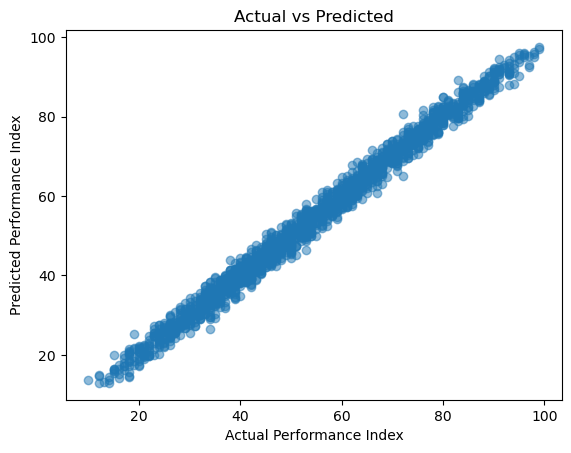

In [32]:
plt.scatter(y_test, predictions, alpha=0.5)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("Actual vs Predicted")
plt.show()

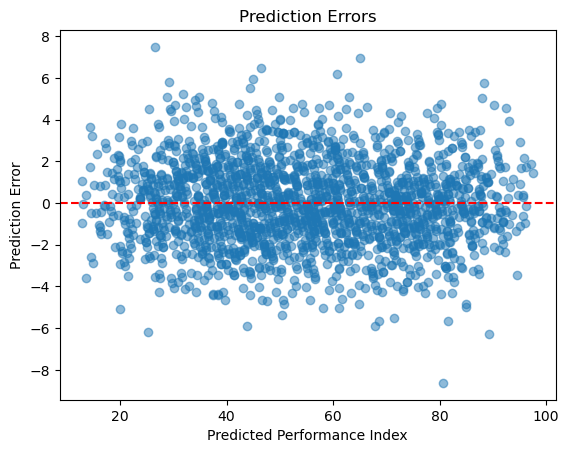

In [33]:
#Check where the model makes mistakes
errors = y_test - predictions

plt.scatter(predictions, errors, alpha=0.5)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Performance Index")
plt.ylabel("Prediction Error")
plt.title("Prediction Errors")
plt.show()

In [34]:
model = models["Linear Regression"]

for name, value in zip(X.columns, model.coef_):
    print(name, ":", round(value, 3))

print("Intercept:", round(model.intercept_, 3))

Hours Studied : 2.859
Previous Scores : 1.019
Extracurricular Activities : 0.61
Sleep Hours : 0.477
Sample Question Papers Practiced : 0.188
Intercept: -34.099


In [35]:
df_clean = df_encoded.drop_duplicates().copy()

print("Original rows:", len(df_encoded))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicates left:", df_clean.duplicated().sum())

Original rows: 10000
Rows after removing duplicates: 9873
Duplicates left: 0


In [36]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df_clean[features]
y = df_clean[target]

groups = df_clean.groupby(features, sort=False).ngroup()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 7904
Testing rows: 1969


In [37]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("MAE").round(3))

,Model,MAE,RMSE,R2
1,Ridge Regression,1.600,2.018,0.989
0,Linear Regression,1.600,2.018,0.989
3,Gradient Boosting,1.654,2.083,0.989
2,Random Forest,1.866,2.333,0.986


In [38]:
from sklearn.linear_model import LinearRegression
import joblib

model = LinearRegression()

X = df_clean[features]
y = df_clean[target]

model.fit(X, y)

joblib.dump(model, "../model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [41]:
student = pd.DataFrame([{
    "Hours Studied": 5,
    "Previous Scores": 70,
    "Extracurricular Activities": 1,
    "Sleep Hours": 7,
    "Sample Question Papers Practiced": 3
}])

prediction = loaded_model.predict(student)

print("Predicted Performance Index:", round(prediction[0], 2))

Predicted Performance Index: 56.04
